# Занятие 6. Кинематика колёсных мобильных роботов — демонстрации

Конспект: лекция 6 (разделы 6.1–6.11). Модуль `wheeled.py`: кинематика дифференциальной схемы, трицикла, омни- и меканум-платформ, три формулы одометрии, рисование платформ и траекторий.
Обозначения: $\mathbf q=(x,y,\theta)^{\mathrm T}$ — положение корпуса, $\mathbf u=(v_x,v_y,\omega)^{\mathrm T}$ — скорость корпуса в связанной системе, $\dot{\boldsymbol\varphi}$ — скорости колёс. Все числа сверяются с примерами 6.1–6.7 конспекта.

| № | Демонстрация | Слайды | Конспект |
|---|---|---|---|
| 1 | МЦВ и три случая движения дифференциальной схемы | 13–14 | § 6.4, пример 6.1 |
| 2 | ПЗК на шаге и одометрия: метод Эйлера против точной дуги | 16–17 | § 6.5, пример 6.3 |
| 3 | ОЗК о скорости и насыщение скоростей колёс: срезание против масштабирования | 15 | § 6.4, пример 6.2 |
| 4 | Трицикл и автомобильная схема, углы Аккермана | 24–25 | § 6.6, пример 6.4 |
| 5 | Трёхколёсная омни-платформа | 26–27 | § 6.7, пример 6.5 |
| 6 | Меканум-платформа: базовые движения, ОЗК и ПЗК о скорости, октаэдр | 28–33 | § 6.8, примеры 6.6, 6.7 |
| 7 | Ранг матрицы связей и манёвренность шасси | 8–10, 36 | § 6.3, 6.9 |
| 8 | Параллельная парковка и манёвр скобки Ли | 37–38 | § 6.10 |
| 9 | Накопление ошибки одометрии на квадрате $4\times4$ м | 18 | § 6.5 |
| 10 | Интерактив: меканум-платформа с ползунками | 33 | — |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from wheeled import *
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians

## 1. МЦВ и три случая движения дифференциальной схемы (§ 6.4, пример 6.1)

$v=\dfrac{V_r+V_l}{2}$, $\omega=\dfrac{V_r-V_l}{l}$, $R=\dfrac{l}{2}\cdot\dfrac{V_r+V_l}{V_r-V_l}$; МЦВ лежит на колёсной оси: $x_c=x-R\sin\theta$, $y_c=y+R\cos\theta$.
Ожидаем для $r=0{,}05$ м, $l=0{,}30$ м, $\dot\varphi_r=12$, $\dot\varphi_l=8$ рад/с: $v=0{,}5$ м/с, $\omega=0{,}667$ рад/с, $R=0{,}75$ м.

пример 6.1: V_r = 0.60, V_l = 0.40 м/с ->  v = 0.500 м/с, omega = 0.667 рад/с, R = 0.750 м;  omega R = 0.500
МЦВ в начальный момент: [0.   0.75]  (слева от робота)
матрица G(0) = R_z(0) F =
 [[ 0.025   0.025 ]
 [ 0.      0.    ]
 [ 0.1667 -0.1667]] 
ранг G = 2 при любом theta


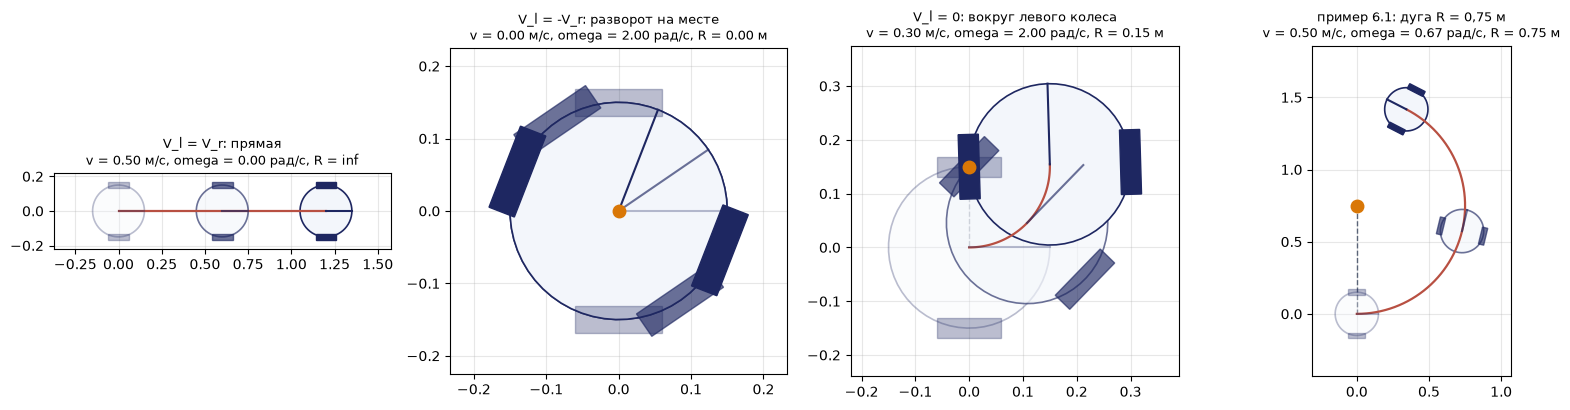

In [2]:
v, w = dd_fk(12.0, 8.0); R, icc = dd_icc(np.zeros(3), v, w)
print('пример 6.1: V_r = %.2f, V_l = %.2f м/с ->  v = %.3f м/с, omega = %.3f рад/с, R = %.3f м;  omega R = %.3f' % (DD_R*12, DD_R*8, v, w, R, w*R))
print('МЦВ в начальный момент:', icc, ' (слева от робота)')
print('матрица G(0) = R_z(0) F =\n', dd_G(0.0), '\nранг G = %d при любом theta' % np.linalg.matrix_rank(dd_G(0.7)))

cases = [('V_l = V_r: прямая', 10.0, 10.0, 2.4), ('V_l = -V_r: разворот на месте', 6.0, -6.0, 0.6), ('V_l = 0: вокруг левого колеса', 12.0, 0.0, 0.8), ('пример 6.1: дуга R = 0,75 м', 12.0, 8.0, 4.0)]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (ttl, pr, pl, T) in zip(axs, cases):
    v, w = dd_fk(pr, pl)
    P = integrate(np.zeros(3), v, w, T/60, 60); draw_path(ax, P)
    for k in (0, 30, 60): draw_diffdrive(ax, P[k], alpha=0.3 + 0.7*k/60)
    R, icc = dd_icc(P[0], v, w)
    if icc is not None:
        ax.plot(icc[0], icc[1], 'o', color=AMB, ms=9, zorder=8); ax.plot([icc[0], P[0, 0]], [icc[1], P[0, 1]], color=GREY, lw=1, ls='--')
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.margins(0.15)
    ax.set_title('%s\nv = %.2f м/с, omega = %.2f рад/с, R = %s' % (ttl, v, w, 'inf' if icc is None else '%.2f м' % R), fontsize=9.5)
plt.tight_layout(); plt.show()

## 2. ПЗК на шаге и одометрия: метод Эйлера против точной дуги (§ 6.5, пример 6.3)

Три формулы обновления положения: метод Эйлера (курс в начале шага), метод средней точки (курс в середине шага), точная дуга (поворот вокруг МЦВ).
$v=0{,}5$ м/с, $\omega=0{,}5$ рад/с, $\delta t=0{,}5$ с, около половины окружности (13 шагов). Ожидаем ошибки положения $0{,}250$ м, $0{,}0052$ м и $0$.

метод Эйлера  : ошибка положения после 13 шагов = 0.2498 м
средняя точка : ошибка положения после 13 шагов = 0.0052 м
точная дуга   : ошибка положения после 13 шагов = 0.0000 м
оценка для средней точки: dtheta^2/24 * перемещение = 0.0026 * 2.00 м = 0.0052 м


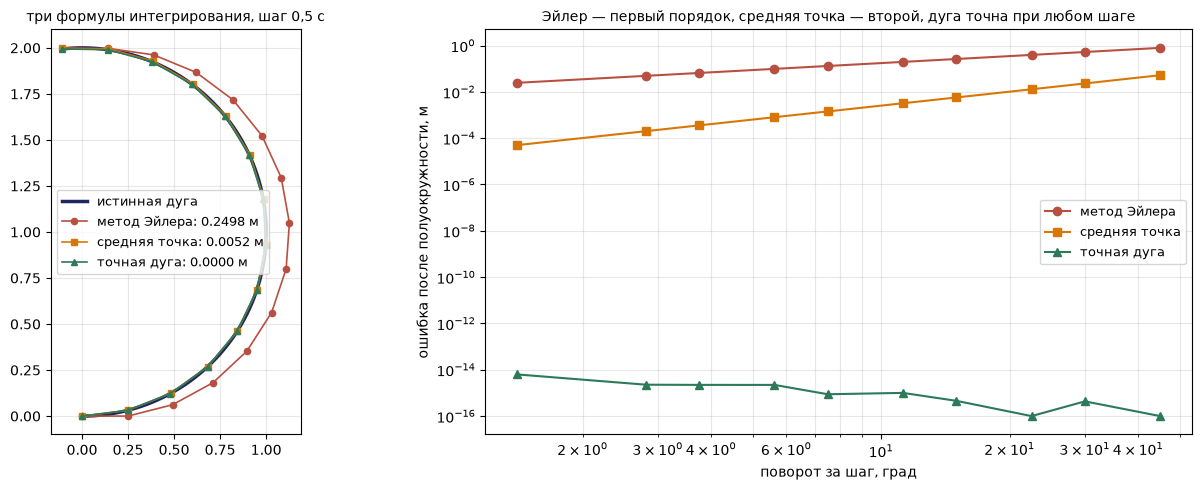

In [3]:
v, w, dt = 0.5, 0.5, 0.5; n = int(round(2*np.pi/dt)); q_true = step_exact(np.zeros(3), v, w, n*dt)
names = {'euler': ('метод Эйлера', RED, 'o'), 'mid': ('средняя точка', AMB, 's'), 'exact': ('точная дуга', GREEN, '^')}
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
ax = axs[0]; t = np.linspace(0, n*dt, 300); ax.plot(v/w*np.sin(w*t), v/w*(1 - np.cos(w*t)), color=NAVY, lw=2.5, label='истинная дуга')
for m, (nm, col, mk) in names.items():
    P = integrate(np.zeros(3), v, w, dt, n, m); err = np.hypot(P[-1, 0] - q_true[0], P[-1, 1] - q_true[1])
    print('%-14s: ошибка положения после %d шагов = %.4f м' % (nm, n, err))
    ax.plot(P[:, 0], P[:, 1], '-' + mk, color=col, lw=1.2, ms=4.5, label='%s: %.4f м' % (nm, err))
print('оценка для средней точки: dtheta^2/24 * перемещение = %.4f * %.2f м = %.4f м' % ((w*dt)**2/24, np.hypot(q_true[0], q_true[1]), (w*dt)**2/24*np.hypot(q_true[0], q_true[1])))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='center left'); ax.set_title('три формулы интегрирования, шаг 0,5 с', fontsize=10)

ax = axs[1]; T = np.pi/w; q_half = step_exact(np.zeros(3), v, w, T); ns = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 128])
for m in ('euler', 'mid', 'exact'):
    errs = [np.hypot(*(integrate(np.zeros(3), v, w, T/k, k, m)[-1, :2] - q_half[:2])) for k in ns]
    ax.loglog(np.degrees(w*T/ns), np.maximum(errs, 1e-16), '-' + names[m][2], color=names[m][1], label=names[m][0])
ax.set_xlabel('поворот за шаг, град'); ax.set_ylabel('ошибка после полуокружности, м'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9)
ax.set_title('Эйлер — первый порядок, средняя точка — второй, дуга точна при любом шаге', fontsize=10)
plt.tight_layout(); plt.show()

## 3. ОЗК о скорости и насыщение скоростей колёс (§ 6.4, пример 6.2)

$\dot\varphi_{r,l}=\dfrac1r\Big(v\pm\dfrac l2\omega\Big)$; ограничение $\lvert\dot\varphi\rvert\le\dot\varphi_{\max}$ даёт ромб $\lvert v\rvert+\dfrac l2\lvert\omega\rvert\le r\dot\varphi_{\max}$.
Команда $v=0{,}8$ м/с, $\omega=2{,}0$ рад/с при $\dot\varphi_{\max}=20$ рад/с. Ожидаем: $22$ и $10$ рад/с; срезание → $0{,}75$ м/с, $1{,}67$ рад/с, $R=0{,}45$ м; масштабирование → $0{,}727$ м/с, $1{,}82$ рад/с, $R=0{,}40$ м.

ОЗК: v = 0.8, omega = 2.0  ->  phi_r = 22.0, phi_l = 10.0 рад/с;  R = 0.40 м
срезание        : phi = (20.00; 10.00) -> v = 0.750 м/с, omega = 1.667 рад/с, R = 0.450 м
масштабирование : phi = (20.00; 9.09) -> v = 0.727 м/с, omega = 1.818 рад/с, R = 0.400 м


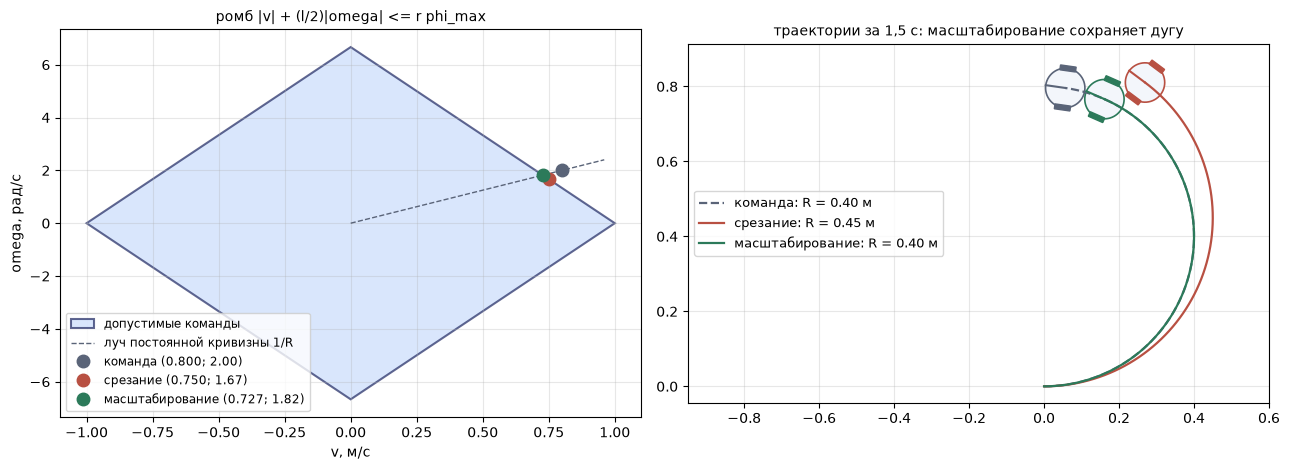

In [4]:
v0, w0, pmax = 0.8, 2.0, 20.0; pr, pl = dd_ik(v0, w0)
print('ОЗК: v = %.1f, omega = %.1f  ->  phi_r = %.1f, phi_l = %.1f рад/с;  R = %.2f м' % (v0, w0, pr, pl, v0/w0))
res = {'команда': (v0, w0)}
for mode, nm in (('clip', 'срезание'), ('scale', 'масштабирование')):
    s = dd_saturate(pr, pl, pmax, mode); vv, ww = dd_fk(s[0], s[1]); res[nm] = (vv, ww)
    print('%-16s: phi = (%.2f; %.2f) -> v = %.3f м/с, omega = %.3f рад/с, R = %.3f м' % (nm, s[0], s[1], vv, ww, vv/ww))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8)); cols = {'команда': GREY, 'срезание': RED, 'масштабирование': GREEN}
ax = axs[0]; vm, wm = DD_R*pmax, 2*DD_R*pmax/DD_L
ax.fill([vm, 0, -vm, 0], [0, wm, 0, -wm], facecolor=ICE, edgecolor=NAVY, lw=1.5, alpha=0.7, label='допустимые команды')
ax.plot([0, 1.2*v0], [0, 1.2*w0], color=GREY, lw=1, ls='--', label='луч постоянной кривизны 1/R')
for nm, (vv, ww) in res.items(): ax.plot(vv, ww, 'o', color=cols[nm], ms=9, label='%s (%.3f; %.2f)' % (nm, vv, ww), zorder=5)
ax.set_xlabel('v, м/с'); ax.set_ylabel('omega, рад/с'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower left'); ax.set_title('ромб |v| + (l/2)|omega| <= r phi_max', fontsize=10)
ax = axs[1]
for nm, (vv, ww) in res.items():
    P = integrate(np.zeros(3), vv, ww, 0.02, 75); draw_path(ax, P, color=cols[nm], label='%s: R = %.2f м' % (nm, vv/ww), ls='--' if nm == 'команда' else '-'); draw_diffdrive(ax, P[-1], color=cols[nm], scale=0.35)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-0.95, 0.6); ax.legend(fontsize=9, loc='center left'); ax.set_title('траектории за 1,5 с: масштабирование сохраняет дугу', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Трицикл и автомобильная схема (§ 6.6, пример 6.4)

Трицикл: $R=d/\operatorname{tg}\delta$; привод на рулевом колесе — $v=v_s\cos\delta$, $\omega=v_s\sin\delta/d$; привод на задней оси — $\omega=v\operatorname{tg}\delta/d$.
Аккерман: $\operatorname{tg}\delta_i=\dfrac{d}{R-l/2}$, $\operatorname{tg}\delta_o=\dfrac{d}{R+l/2}$, $\operatorname{ctg}\delta_o-\operatorname{ctg}\delta_i=l/d$.
Ожидаем при $d=2{,}7$, $l=1{,}6$, $R=6$ м: $\delta_i=27{,}4^\circ$, $\delta_o=21{,}7^\circ$, $\delta=24{,}2^\circ$, отношение скоростей задних колёс $1{,}31$.

пример 6.4: delta_i = 27.4, delta_o = 21.7, эквивалентный трицикл delta = 24.2 град
условие Аккермана: ctg(delta_o) - ctg(delta_i) = 0.593,  l/d = 0.593
задние колёса: радиусы 5.2 и 6.8 м, отношение скоростей = 1.31
ранг матрицы связей C1: углы Аккермана — 2 (МЦВ существует); одинаковые углы — 3 (без скольжения ехать нельзя)
трицикл, d = 1,2 м, руль 30 град, скорость 1 м/с: передний привод (v, omega) = (0.866; 0.417), задний привод = (1.000; 0.481)


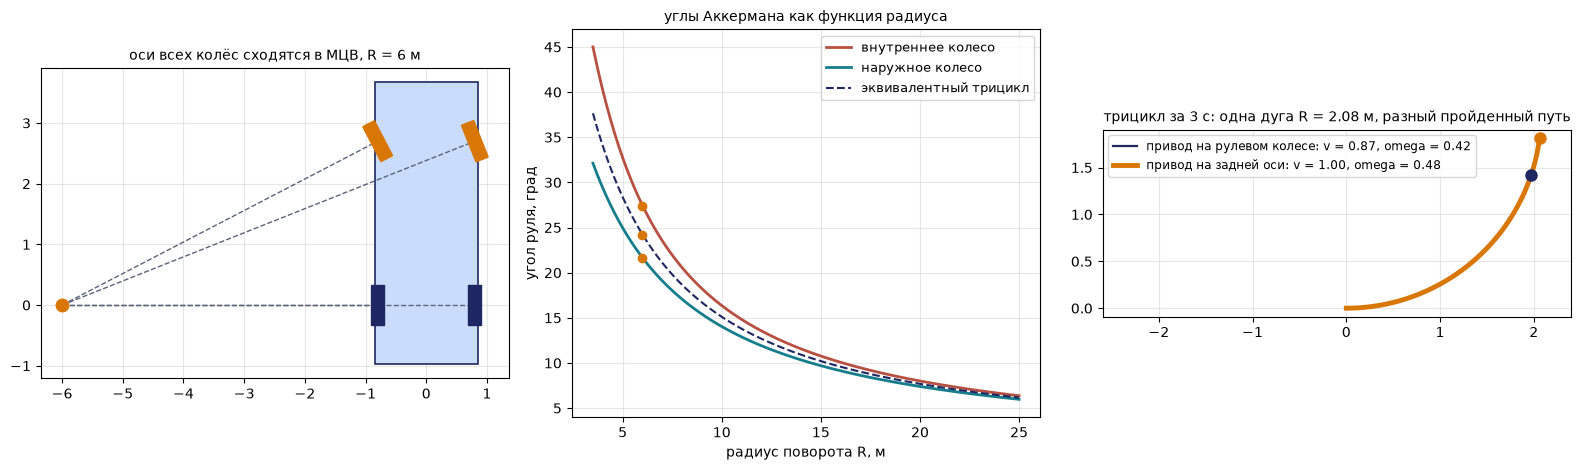

In [5]:
R0 = 6.0; di, do, de = ackermann(R0); Vi, Vo = rear_wheel_speeds(1.0, R0, ACK_L)
print('пример 6.4: delta_i = %.1f, delta_o = %.1f, эквивалентный трицикл delta = %.1f град' % (deg(di), deg(do), deg(de)))
print('условие Аккермана: ctg(delta_o) - ctg(delta_i) = %.3f,  l/d = %.3f' % (1/np.tan(do) - 1/np.tan(di), ACK_L/ACK_D))
print('задние колёса: радиусы %.1f и %.1f м, отношение скоростей = %.2f' % (R0 - ACK_L/2, R0 + ACK_L/2, Vo/Vi))
C = np.array([slide_row(np.pi/2, 0, ACK_L/2), slide_row(np.arctan2(ACK_L/2, ACK_D), np.pi/2 + di - np.arctan2(ACK_L/2, ACK_D), np.hypot(ACK_D, ACK_L/2)),
              slide_row(np.arctan2(-ACK_L/2, ACK_D), np.pi/2 + do - np.arctan2(-ACK_L/2, ACK_D), np.hypot(ACK_D, ACK_L/2))])
C_bad = C.copy(); C_bad[2] = slide_row(np.arctan2(-ACK_L/2, ACK_D), np.pi/2 + di - np.arctan2(-ACK_L/2, ACK_D), np.hypot(ACK_D, ACK_L/2))
print('ранг матрицы связей C1: углы Аккермана — %d (МЦВ существует); одинаковые углы — %d (без скольжения ехать нельзя)' % (np.linalg.matrix_rank(C, tol=1e-9), np.linalg.matrix_rank(C_bad, tol=1e-9)))
vs, dl, dd_ = 1.0, rad(30.0), 1.2
print('трицикл, d = 1,2 м, руль 30 град, скорость 1 м/с: передний привод (v, omega) = (%.3f; %.3f), задний привод = (%.3f; %.3f)' % (tri_front(vs, dl, dd_) + tri_rear(vs, dl, dd_)))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axs[0]; q0 = np.array([0.0, 0.0, np.pi/2]); draw_car(ax, q0, di=di, do=do); icc = np.array([-R0, 0.0])
for pt in ((0.0, ACK_L/2), (0.0, -ACK_L/2), (ACK_D, ACK_L/2), (ACK_D, -ACK_L/2)):
    pw = np.array([-pt[1], pt[0]]); ax.plot([icc[0], pw[0]], [icc[1], pw[1]], color=GREY, lw=1, ls='--')
ax.plot(icc[0], icc[1], 'o', color=AMB, ms=9); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('оси всех колёс сходятся в МЦВ, R = 6 м', fontsize=10)
ax = axs[1]; Rs = np.linspace(3.5, 25, 200); a = np.array([ackermann(R_) for R_ in Rs])
ax.plot(Rs, deg(a[:, 0]), color=RED, lw=2, label='внутреннее колесо'); ax.plot(Rs, deg(a[:, 1]), color=TEAL, lw=2, label='наружное колесо'); ax.plot(Rs, deg(a[:, 2]), color=NAVY, lw=1.5, ls='--', label='эквивалентный трицикл')
ax.plot([R0]*3, deg([di, do, de]), 'o', color=AMB); ax.set_xlabel('радиус поворота R, м'); ax.set_ylabel('угол руля, град'); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_title('углы Аккермана как функция радиуса', fontsize=10)
ax = axs[2]
for nm, (vv, ww), col in (('привод на рулевом колесе', tri_front(vs, dl, dd_), NAVY), ('привод на задней оси', tri_rear(vs, dl, dd_), AMB)):
    Pt = integrate(np.zeros(3), vv, ww, 0.05, 60); draw_path(ax, Pt, color=col, lw=3.5 if col == AMB else 1.6, label='%s: v = %.2f, omega = %.2f' % (nm, vv, ww)); ax.plot(Pt[-1, 0], Pt[-1, 1], 'o', color=col, ms=8, zorder=6)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-2.6, 2.4); ax.legend(fontsize=8.5, loc='upper left'); ax.set_title('трицикл за 3 с: одна дуга R = %.2f м, разный пройденный путь' % (dd_/np.tan(dl)), fontsize=10)
plt.tight_layout(); plt.show()

## 5. Трёхколёсная омни-платформа (§ 6.7, пример 6.5)

Из связей сразу получается обратная задача: $r\dot\varphi_i=-\sin\alpha_i\,v_x+\cos\alpha_i\,v_y+L\omega$, $\dot{\boldsymbol\varphi}=H\mathbf u$; прямая — обращением $H$.
Ожидаем при $r=0{,}05$, $L=0{,}20$ м, $\mathbf u=(0{,}2;\ 0{,}1;\ 0{,}5)$: $\dot{\boldsymbol\varphi}=(4{,}00;\ -2{,}46;\ 4{,}46)$ рад/с, $\det H=3\sqrt3L/(2r^3)$.
Затем — движение по прямой с одновременным вращением: скорости колёс меняются по гармоническому закону.

H =
 [[  0.      20.       4.    ]
 [-17.3205 -10.       4.    ]
 [ 17.3205 -10.       4.    ]] 
det H = 4156.9,  3*sqrt(3)*L/(2 r^3) = 4156.9
H^-1 =
 [[ 0.     -0.0289  0.0289]
 [ 0.0333 -0.0167 -0.0167]
 [ 0.0833  0.0833  0.0833]]
пример 6.5: phi_dot = [ 4.   -2.46  4.46] рад/с;  обратно u = H^-1 phi = [0.2 0.1 0.5]
чистое движение вперёд u = (0.3, 0, 0): phi_dot = [ 0.    -5.196  5.196]  (первое колесо стоит, sqrt(3) v/(2r) = 5.196)


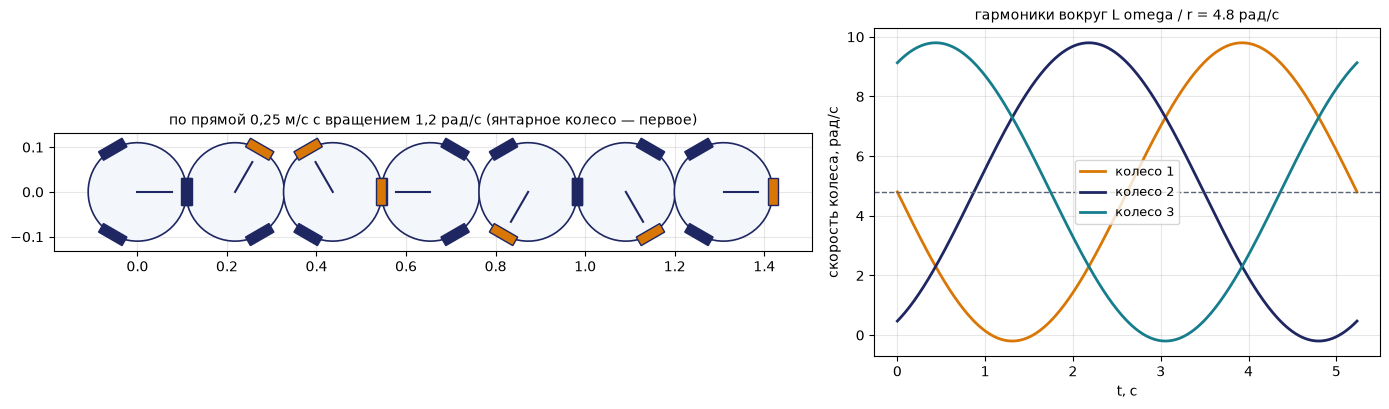

In [6]:
H = omni_H(); u = np.array([0.2, 0.1, 0.5]); phi = H.dot(u)
print('H =\n', H + 0.0, '\ndet H = %.1f,  3*sqrt(3)*L/(2 r^3) = %.1f' % (np.linalg.det(H), 3*np.sqrt(3)*OMNI_LL/(2*OMNI_R**3)))
print('H^-1 =\n', np.linalg.inv(H))
print('пример 6.5: phi_dot =', phi.round(2), 'рад/с;  обратно u = H^-1 phi =', np.linalg.solve(H, phi).round(4))
print('чистое движение вперёд u = (0.3, 0, 0): phi_dot =', H.dot([0.3, 0, 0]).round(3), ' (первое колесо стоит, sqrt(3) v/(2r) = %.3f)' % (np.sqrt(3)*0.3/(2*OMNI_R)))

qd = np.array([0.25, 0.0, 1.2]); T = 2*np.pi/qd[2]; ts = np.linspace(0, T, 300)
ph = np.array([H.dot(rotz(qd[2]*t).T.dot(qd)) for t in ts])
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axs[0]; ax.plot(qd[0]*ts, 0*ts, color=RED, lw=1.5)
for t in np.linspace(0, T, 7): draw_omni3(ax, np.array([qd[0]*t, 0.0, qd[2]*t]), scale=0.55)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('по прямой 0,25 м/с с вращением 1,2 рад/с (янтарное колесо — первое)', fontsize=10)
ax = axs[1]
for i, col in enumerate((AMB, NAVY, TEAL)): ax.plot(ts, ph[:, i], color=col, lw=2, label='колесо %d' % (i + 1))
ax.axhline(OMNI_LL*qd[2]/OMNI_R, color=GREY, ls='--', lw=1); ax.set_xlabel('t, с'); ax.set_ylabel('скорость колеса, рад/с'); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title('гармоники вокруг L omega / r = %.1f рад/с' % (OMNI_LL*qd[2]/OMNI_R), fontsize=10)
plt.tight_layout(); plt.show()

## 6. Меканум-платформа (§ 6.8, примеры 6.6 и 6.7)

$r\dot\varphi_{1,4}=v_x-v_y\mp(l_x+l_y)\omega$, $r\dot\varphi_{2,3}=v_x+v_y\pm(l_x+l_y)\omega$; прямая задача — псевдообратной матрицей $H^{+}=(H^{\mathrm T}H)^{-1}H^{\mathrm T}$; условие совместности $\dot\varphi_1+\dot\varphi_2-\dot\varphi_3-\dot\varphi_4=0$.
Ожидаем ($r=0{,}05$, $l_x=0{,}235$, $l_y=0{,}15$ м): пример 6.6 — $\mathbf u=(0{,}3;0{,}2;0{,}5)\to\dot{\boldsymbol\varphi}=(-1{,}85;\ 13{,}85;\ 6{,}15;\ 5{,}85)$; пример 6.7 — невязка совместности $0{,}6$, $\mathbf u\approx(0{,}503;\ -0{,}0025;\ 0{,}032)$.

H =
 [[ 20.  -20.   -7.7]
 [ 20.   20.    7.7]
 [ 20.   20.   -7.7]
 [ 20.  -20.    7.7]] 
H^T H = diag [1600.  1600.   237.2] ;  max |H+ - pinv(H)| = 1.4e-17

базовые движения (скорости колёс 1..4, рад/с):
  вперёд                     u = (0.3, 0, 0)      phi_dot = [6. 6. 6. 6.]
  влево                      u = (0, 0.3, 0)      phi_dot = [-6.  6.  6. -6.]
  вправо                     u = (0, -0.3, 0)     phi_dot = [ 6. -6. -6.  6.]
  диагональ вперёд-влево     u = (0.3, 0.3, 0)    phi_dot = [ 0. 12. 12.  0.]
  диагональ вперёд-вправо    u = (0.3, -0.3, 0)   phi_dot = [12.  0.  0. 12.]
  поворот против часовой     u = (0, 0, 1.0)      phi_dot = [-7.7  7.7 -7.7  7.7]

пример 6.6: phi_dot = [-1.85 13.85  6.15  5.85] ;  совместность = 0.0e+00;  ПЗК обратно u = [0.3 0.2 0.5] ;  phi2/|phi1| = 7.5
пример 6.7: совместность = 0.6;  u = (0.5025; -0.0025; 0.0325);  невязка = [ 0.15  0.15 -0.15 -0.15] рад/с
ограничения при phi_max = 20 рад/с: вперёд 1.00, по диагонали 0.71 м/с, поворот 2.60 рад/с

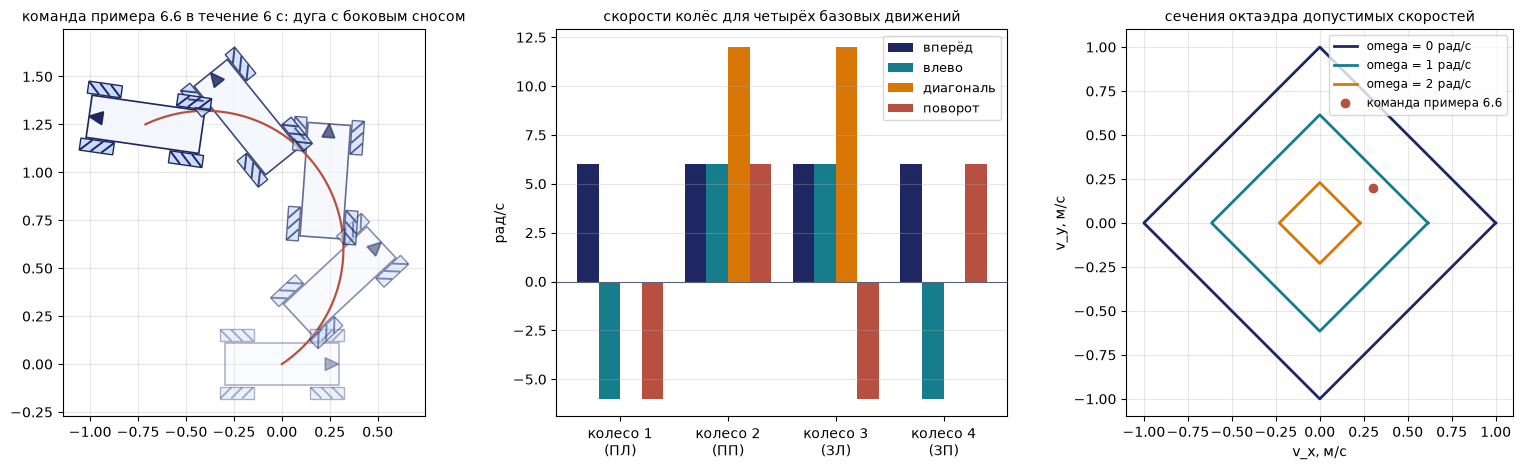

In [7]:
H = mec_H(); Hp = mec_Hpinv()
print('H =\n', H, '\nH^T H = diag', np.diag(H.T.dot(H)).round(1), ';  max |H+ - pinv(H)| = %.1e' % np.abs(Hp - np.linalg.pinv(H)).max())
print('\nбазовые движения (скорости колёс 1..4, рад/с):')
for nm, u in (('вперёд', (0.3, 0, 0)), ('влево', (0, 0.3, 0)), ('вправо', (0, -0.3, 0)), ('диагональ вперёд-влево', (0.3, 0.3, 0)), ('диагональ вперёд-вправо', (0.3, -0.3, 0)), ('поворот против часовой', (0, 0, 1.0))):
    print('  %-26s u = %-16s phi_dot = %s' % (nm, str(u), H.dot(u).round(2) + 0.0))
u66 = np.array([0.3, 0.2, 0.5]); phi66 = H.dot(u66); u_back, res, comp = mec_fk(phi66)
print('\nпример 6.6: phi_dot =', phi66.round(2), ';  совместность = %.1e;  ПЗК обратно u =' % comp, u_back.round(4), ';  phi2/|phi1| = %.1f' % (phi66[1]/abs(phi66[0])))
u67, res67, comp67 = mec_fk([10.0, 10.4, 9.6, 10.2])
print('пример 6.7: совместность = %.1f;  u = (%.4f; %.4f; %.4f);  невязка =' % ((comp67,) + tuple(u67)), res67.round(3), 'рад/с')
print('ограничения при phi_max = 20 рад/с: вперёд %.2f, по диагонали %.2f м/с, поворот %.2f рад/с' % (mec_vmax(0.0), mec_vmax(np.pi/4), MEC_R*20/(MEC_LX + MEC_LY)))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axs[0]; P = simulate_body(lambda t: u66, T=6.0, n=300); draw_path(ax, P)
for k in (0, 75, 150, 225, 300): draw_mecanum(ax, P[k], alpha=0.35 + 0.65*k/300)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('команда примера 6.6 в течение 6 с: дуга с боковым сносом', fontsize=10)
ax = axs[1]; lab = ['вперёд', 'влево', 'диагональ', 'поворот']; us = [(0.3, 0, 0), (0, 0.3, 0), (0.3, 0.3, 0), (0, 0, 0.78)]; wdt = 0.2
for i, u in enumerate(us):
    ph = H.dot(u); ax.bar(np.arange(4) + i*wdt - 0.3, ph, wdt, color=(NAVY, TEAL, AMB, RED)[i], label=lab[i])
ax.axhline(0, color=GREY, lw=.8); ax.set_xticks(range(4)); ax.set_xticklabels(['колесо 1\n(ПЛ)', 'колесо 2\n(ПП)', 'колесо 3\n(ЗЛ)', 'колесо 4\n(ЗП)']); ax.set_ylabel('рад/с'); ax.grid(alpha=.3, axis='y'); ax.legend(fontsize=9)
ax.set_title('скорости колёс для четырёх базовых движений', fontsize=10)
ax = axs[2]; aa = np.linspace(0, 2*np.pi, 361)
for om, col in ((0.0, NAVY), (1.0, TEAL), (2.0, AMB)):
    rr = np.array([mec_vmax(a_, om) for a_ in aa]); ax.plot(rr*np.cos(aa), rr*np.sin(aa), color=col, lw=2, label='omega = %.0f рад/с' % om)
ax.plot(0.3, 0.2, 'o', color=RED, label='команда примера 6.6'); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper right'); ax.set_xlabel('v_x, м/с'); ax.set_ylabel('v_y, м/с')
ax.set_title('сечения октаэдра допустимых скоростей', fontsize=10)
plt.tight_layout(); plt.show()

## 7. Ранг матрицы связей и манёвренность шасси (§ 6.3, 6.9)

Строка условия отсутствия бокового скольжения колеса с параметрами $(\alpha,\beta,l)$: $\big(\cos(\alpha+\beta),\ \sin(\alpha+\beta),\ l\sin\beta\big)$. Матрица $C_1$ собирается из строк фиксированных и рулевых колёс;
$\delta_m=3-\operatorname{rank}C_1$, $\delta_s=\operatorname{rank}C_{1s}$, $\delta_M=\delta_m+\delta_s$. Ожидаем пять типов шасси $(3,0)$, $(2,0)$, $(2,1)$, $(1,1)$, $(1,2)$ и $\delta_m=0$ для тележки с тремя фиксированными колёсами, оси которых не сходятся в одной точке.

In [8]:
print('связи колёс дифференциальной схемы (l = 0,30 м):')
for nm, (al, be) in (('левое', (np.pi/2, 0.0)), ('правое', (-np.pi/2, np.pi))):
    print('  %-7s качение: %s u = r phi_dot;   скольжение: %s u = 0' % (nm, (roll_row(al, be, DD_L/2) + 0.0).round(3), (slide_row(al, be, DD_L/2) + 0.0).round(3)))
print('шведское колесо при gamma = 0 совпадает с условием качения:', np.allclose(swedish_row(0.3, 0.4, 0.0, 0.2), roll_row(0.3, 0.4, 0.2)))

dl = rad(25.0); chassis = [
    ('омни- или меканум-платформа',            [], []),
    ('дифференциальная схема',                 [(np.pi/2, 0.0, 0.15), (-np.pi/2, np.pi, 0.15)], []),
    ('одно рулевое колесо и пассивные опоры',  [], [(0.0, np.pi/2 + dl, 0.2)]),
    ('трицикл (велосипед, автомобиль)',        [(np.pi/2, 0.0, 0.3), (-np.pi/2, np.pi, 0.3)], [(0.0, np.pi/2 + dl, 1.2)]),
    ('два независимых рулевых колеса',         [], [(0.0, np.pi/2 + dl, 0.4), (np.pi, np.pi/2 - rad(15.0), 0.4)]),
    ('тележка с тремя фиксированными колёсами', [(0.0, np.pi/2, 0.3), (2*np.pi/3, np.pi/2, 0.3), (4*np.pi/3, 0.3, 0.3)], []),
]
print('\n%-42s %7s %8s %8s %8s' % ('шасси', 'rank C1', 'delta_m', 'delta_s', 'delta_M'))
for nm, fx, st in chassis:
    C1, rk, dm, ds, dM = maneuverability(fx, st); print('%-42s %7d %8d %8d %8d' % (nm, rk, dm, ds, dM))
C1 = maneuverability(*chassis[3][1:])[0]; _, _, Vt = np.linalg.svd(C1); u_ok = Vt[-1]/Vt[-1][0]
print('\nтрицикл: допустимая скорость корпуса (ядро C1) u ~', u_ok.round(4), ';  omega/v = %.4f = tg(delta)/d = %.4f' % (u_ok[2], np.tan(dl)/1.2))

связи колёс дифференциальной схемы (l = 0,30 м):
  левое   качение: [ 1.   -0.   -0.15] u = r phi_dot;   скольжение: [0. 1. 0.] u = 0
  правое  качение: [ 1.   -0.    0.15] u = r phi_dot;   скольжение: [0. 1. 0.] u = 0
шведское колесо при gamma = 0 совпадает с условием качения: True

шасси                                      rank C1  delta_m  delta_s  delta_M
омни- или меканум-платформа                      0        3        0        3
дифференциальная схема                           1        2        0        2
одно рулевое колесо и пассивные опоры            1        2        1        3
трицикл (велосипед, автомобиль)                  2        1        1        2
два независимых рулевых колеса                   2        1        2        3
тележка с тремя фиксированными колёсами          3        0        0        0

трицикл: допустимая скорость корпуса (ядро C1) u ~ [ 1.     -0.      0.3886] ;  omega/v = 0.3886 = tg(delta)/d = 0.3886


## 8. Параллельная парковка и манёвр скобки Ли (§ 6.10)

Велосипедная модель, $R_{\min}=4$ м: задний ход по дуге $\psi=20^\circ$ с рулём вправо, затем влево, возврат вперёд. Ожидаем сдвиг за цикл $2R(1-\cos\psi)=0{,}482$ м, вдоль дороги $2R\sin\psi=2{,}74$ м, за четыре цикла $1{,}93$ м.
Манёвр «вперёд $\varepsilon$ — поворот $\varepsilon$ — назад $\varepsilon$ — поворот $-\varepsilon$» для уницикла: при $\varepsilon=0{,}6$ итог $(0{,}105;\ -0{,}339)$ при предсказании $\varepsilon^2[\mathbf g_1,\mathbf g_2]=(0;\ -0{,}36)$.

сдвиг за цикл: 2R(1 - cos psi) = 0.482 м  (R psi^2 = 0.487);  место вдоль дороги: 2R sin psi = 2.74 м
после циклов 1..4: y = [-0.482 -0.965 -1.447 -1.93 ] ;  курс в конце = -1.7e-17 рад
скобка Ли численно при theta = 0,7: [ 0.6442 -0.7648  0.    ] ;  (sin, -cos, 0) = [ 0.6442 -0.7648  0.    ] ;  det[g1 g2 [g1,g2]] = 1.000
манёвр при eps = 0,6: итог = (0.105; -0.339), курс 2.8e-17;  eps^2 = 0.36


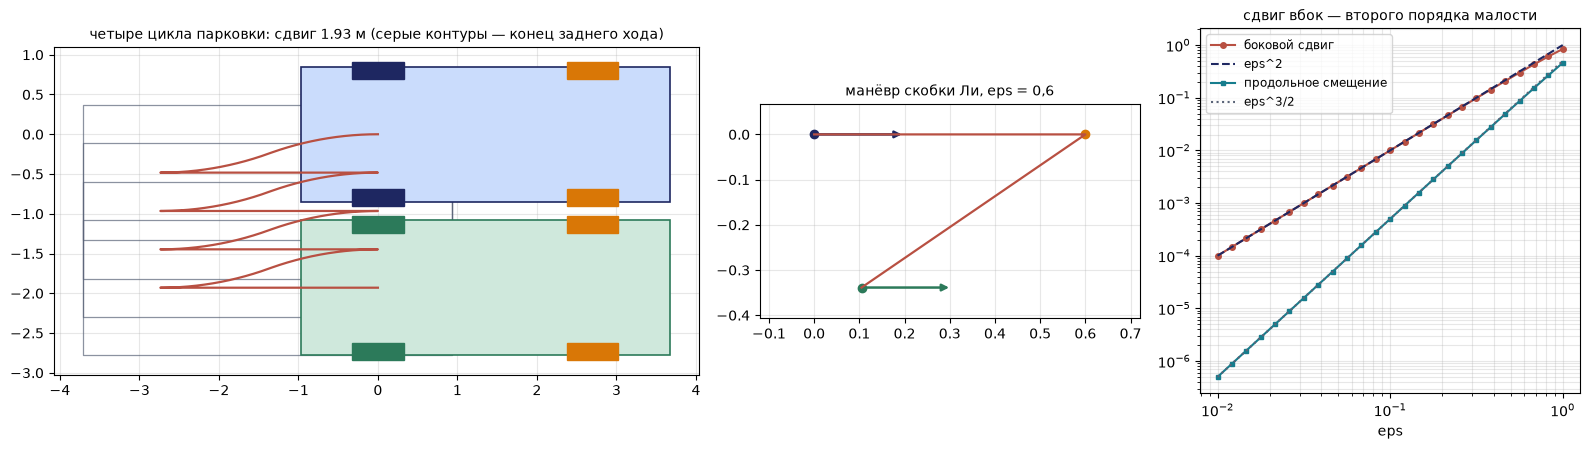

In [9]:
Rm, psi = 4.0, rad(20.0); path, keys = parking_path(Rm, psi, 4)
print('сдвиг за цикл: 2R(1 - cos psi) = %.3f м  (R psi^2 = %.3f);  место вдоль дороги: 2R sin psi = %.2f м' % (2*Rm*(1 - np.cos(psi)), Rm*psi**2, 2*Rm*np.sin(psi)))
print('после циклов 1..4: y =', keys[3::3, 1].round(3), ';  курс в конце = %.1e рад' % keys[-1, 2])
q0 = np.array([0.3, -0.2, 0.7]); br = lie_bracket_num(g1, g2, q0)
print('скобка Ли численно при theta = 0,7:', br.round(5), ';  (sin, -cos, 0) =', np.array([np.sin(0.7), -np.cos(0.7), 0]).round(5), ';  det[g1 g2 [g1,g2]] = %.3f' % np.linalg.det(np.column_stack([g1(q0), g2(q0), br])))
P, marks = lie_maneuver(0.6); print('манёвр при eps = 0,6: итог = (%.3f; %.3f), курс %.1e;  eps^2 = %.2f' % (marks[-1, 0], marks[-1, 1], marks[-1, 2], 0.36))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.7, 1, 1]})
ax = axs[0]
for kq in keys[2:-1:3]: draw_car(ax, kq, fill=False, wheels=False, color=GREY, alpha=0.7)
draw_car(ax, keys[0], fc=ICE); draw_car(ax, keys[-1], fc='#CFE8DC', color=GREEN); draw_path(ax, path)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('четыре цикла парковки: сдвиг %.2f м (серые контуры — конец заднего хода)' % abs(keys[-1, 1]), fontsize=10)
ax = axs[1]; draw_path(ax, P)
for m, col in zip(marks[[0, 2, 4]], (NAVY, AMB, GREEN)):
    ax.annotate('', xy=(m[0] + 0.2*np.cos(m[2]), m[1] + 0.2*np.sin(m[2])), xytext=(m[0], m[1]), arrowprops=dict(arrowstyle='-|>', color=col, lw=1.8)); ax.plot(m[0], m[1], 'o', color=col)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.margins(0.2); ax.set_title('манёвр скобки Ли, eps = 0,6', fontsize=10)
ax = axs[2]; es = np.logspace(-2, 0, 25); ends = np.array([lie_maneuver(e)[1][-1] for e in es])
ax.loglog(es, -ends[:, 1], 'o-', color=RED, ms=4, label='боковой сдвиг'); ax.loglog(es, es**2, color=NAVY, ls='--', label='eps^2'); ax.loglog(es, ends[:, 0], 's-', color=TEAL, ms=3, label='продольное смещение'); ax.loglog(es, es**3/2, color=GREY, ls=':', label='eps^3/2')
ax.set_xlabel('eps'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8.5); ax.set_title('сдвиг вбок — второго порядка малости', fontsize=10)
plt.tight_layout(); plt.show()

## 9. Накопление ошибки одометрии при неравных радиусах колёс (§ 6.5)

Робот отрабатывает квадрат $4\times4$ м по номинальной модели ($r=0{,}05$, $l=0{,}30$ м); одометрия считает, что он вернулся в начало. На самом деле: (а) диаметры колёс различаются на один процент (правое больше), (б) колея больше расчётной на три процента.
Ожидаем при обходе против часовой стрелки: (а) конечная точка $(1{,}216;\ -0{,}694)$ м, ошибка курса $30{,}6^\circ$; (б) $(-0{,}348;\ 0{,}399)$ м. Обход в обе стороны — идея теста UMBmark: ошибка диаметров и ошибка колеи по-разному смещают конечные точки.

диаметры: правое колесо больше на 1 %    против часовой         конец = (1.216; -0.694) м, удаление 1.40 м, ошибка курса 30.6 град
диаметры: правое колесо больше на 1 %    по часовой             конец = (-0.793; -1.389) м, удаление 1.60 м, ошибка курса 30.6 град
колея больше расчётной на 3 %            против часовой         конец = (-0.348; 0.399) м, удаление 0.53 м, ошибка курса -10.5 град
колея больше расчётной на 3 %            по часовой             конец = (-0.348; -0.399) м, удаление 0.53 м, ошибка курса 10.5 град
прямая 4 м при разнице диаметров 1 %: поворот 0.133 рад = 7.6 град, боковой уход 0.27 м
ошибка колеи: каждый поворот на 90 град короче на 2.6 град


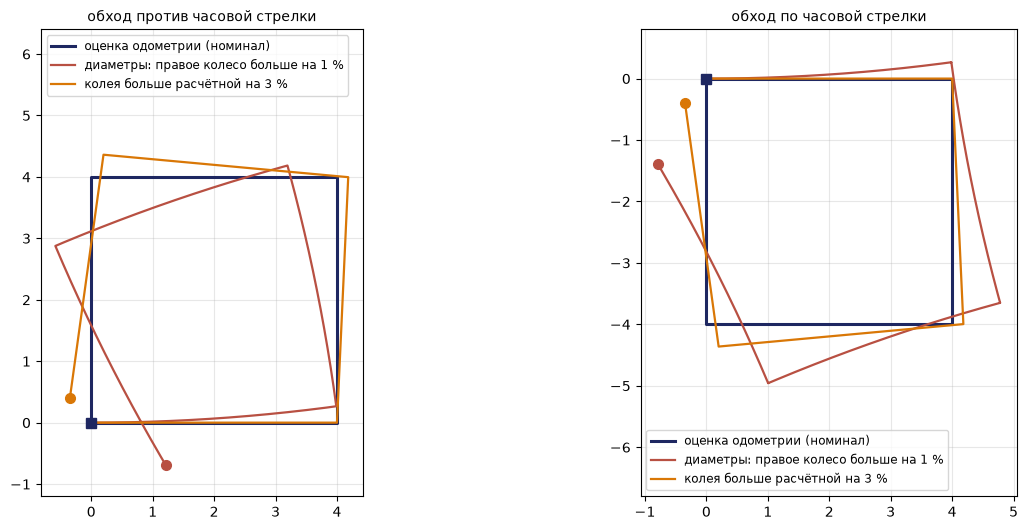

In [10]:
wrap = lambda a: (a + np.pi) % (2*np.pi) - np.pi
runs = {}
for nm, (rr, rl, base) in (('диаметры: правое колесо больше на 1 %', (0.05*1.005, 0.05*0.995, 0.30)), ('колея больше расчётной на 3 %', (0.05, 0.05, 0.30*1.03))):
    for ccw in (True, False):
        P = square_run(rr, rl, base, ccw=ccw); runs[(nm, ccw)] = P
        print('%-40s %-22s конец = (%.3f; %.3f) м, удаление %.2f м, ошибка курса %.1f град' % (nm, 'против часовой' if ccw else 'по часовой', P[-1, 0], P[-1, 1], np.hypot(P[-1, 0], P[-1, 1]), deg(wrap(P[-1, 2]))))
print('прямая 4 м при разнице диаметров 1 %%: поворот %.3f рад = %.1f град, боковой уход %.2f м' % (0.01*4/0.30, deg(0.01*4/0.30), runs[('диаметры: правое колесо больше на 1 %', True)][200, 1]))
print('ошибка колеи: каждый поворот на 90 град короче на %.1f град' % (90 - 90/1.03))
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, ccw in zip(axs, (True, False)):
    sq = np.array([[0, 0], [4, 0], [4, 4], [0, 4], [0, 0]], float) * [1, 1 if ccw else -1]
    ax.plot(sq[:, 0], sq[:, 1], color=NAVY, lw=2.2, label='оценка одометрии (номинал)')
    for (nm, c_), P in runs.items():
        if c_ != ccw: continue
        col = RED if 'диаметры' in nm else AMB; ax.plot(P[:, 0], P[:, 1], color=col, lw=1.6, label=nm); ax.plot(P[-1, 0], P[-1, 1], 'o', color=col, ms=7, zorder=6)
    ax.plot(0, 0, 's', color=NAVY, ms=7); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_ylim((-1.2, 6.4) if ccw else (-6.8, 0.8)); ax.legend(fontsize=8.5, loc='upper left' if ccw else 'lower left')
    ax.set_title('обход %s стрелки' % ('против часовой' if ccw else 'по часовой'), fontsize=10)
plt.tight_layout(); plt.show()

## 10. Интерактив: меканум-платформа с ползунками $v_x$, $v_y$, $\omega$ (запускать вживую)

Показывает скорости четырёх колёс, выход за ограничение $\dot\varphi_{\max}=20$ рад/с, положение МЦВ и траекторию за 4 с. При $v_y=0$ платформа ведёт себя как дифференциальная схема: МЦВ лежит на поперечной оси.

In [11]:
try:
    from ipywidgets import interact, FloatSlider
    def show_mecanum(vx=0.3, vy=0.2, omega=0.5):
        u = np.array([vx, vy, omega]); ph = mec_H().dot(u); over = np.abs(ph).max() > 20.0
        fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
        ax = axs[0]; P = simulate_body(lambda t: u, T=4.0, n=200); draw_path(ax, P)
        for k in (0, 100, 200): draw_mecanum(ax, P[k], alpha=0.4 + 0.6*k/200)
        if abs(omega) > 1e-6:
            icc = np.array([-vy/omega, vx/omega]); ax.plot(icc[0], icc[1], 'o', color=AMB, ms=9); ax.annotate('МЦВ', icc, textcoords='offset points', xytext=(6, 6), color=AMB)
        ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('траектория за 4 с; u = (%.2f; %.2f; %.2f)' % (vx, vy, omega), fontsize=10)
        ax = axs[1]; ax.bar(range(1, 5), ph, color=[RED if abs(p) > 20 else NAVY for p in ph]); ax.axhline(20, color=GREY, ls='--'); ax.axhline(-20, color=GREY, ls='--'); ax.axhline(0, color=GREY, lw=.8)
        ax.set_xticks(range(1, 5)); ax.set_xlabel('колесо'); ax.set_ylabel('рад/с'); ax.grid(alpha=.3, axis='y')
        ax.set_title('скорости колёс' + (': ВНЕ октаэдра, команду нужно масштабировать' if over else ''), color=RED if over else NAVY, fontsize=10)
        plt.show()
    interact(show_mecanum, vx=FloatSlider(min=-1, max=1, step=0.05, value=0.3), vy=FloatSlider(min=-1, max=1, step=0.05, value=0.2), omega=FloatSlider(min=-2.6, max=2.6, step=0.1, value=0.5))
except ImportError:
    print('установите ipywidgets: pip install ipywidgets')

interactive(children=(FloatSlider(value=0.3, description='vx', max=1.0, min=-1.0, step=0.05), FloatSlider(valu…